# Landsat8 最新结果整理

- 主 RD 数据：1700 张全测试集，BPP 为 likelihood-BPP。
- `Our-Hybrid-600`：Hybrid-Parallel 模型 600 epochs 最终重测结果。
- `GLIC-val`：200 张缩减验证集上的临时结果，不参与正式 BD-Rate 计算。
- 真实编解码时间：30 张图像，5 张预热，BPP 按真实码流字节计算。

likelihood-BPP 与真实码流 BPP 是两套协议，不混合计算。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT_CANDIDATES = [
    Path('/data/huzhenghao/ml/h/并行优化'),
    Path.cwd(),
    Path.cwd() / '并行优化',
]
OPT_ROOT = next(p for p in ROOT_CANDIDATES if (p / 'final_results/landsat8_hybrid_600').is_dir())
RD_CSV = OPT_ROOT / 'final_results/landsat8_hybrid_600/landsat8_full_rd.csv'

method_labels = {
    'elic': 'ELIC', 'rwk': 'RWK', 'hl': 'HL', 'mlic': 'MLIC',
    'ftic': 'FTIC', 'hpcm': 'HPCM', 'our': 'Our-Original',
    'hybrid_parallel': 'Our-Hybrid-600',
}
landsat8_rd = pd.read_csv(RD_CSV)
landsat8_rd = landsat8_rd[landsat8_rd['Dataset'].str.lower().eq('landsat8')].copy()
landsat8_rd['Label'] = landsat8_rd['Method'].str.lower().map(method_labels)
landsat8_rd = landsat8_rd.sort_values(['Label', 'bpp']).reset_index(drop=True)
landsat8_full_test_1700 = {
    label: list(group.sort_values('bpp')[['bpp', 'psnr', 'ms_ssim_db']].itertuples(index=False, name=None))
    for label, group in landsat8_rd.groupby('Label', sort=False)
}
print(f'source: {RD_CSV}')
print({name: len(points) for name, points in landsat8_full_test_1700.items()})
display(landsat8_rd[['Label', 'Lambda', 'images', 'bpp', 'psnr', 'ms_ssim_db']].round(6))

source: /data/huzhenghao/ml/h/并行优化/final_results/landsat8_hybrid_600/landsat8_full_rd.csv
{'ELIC': 7, 'FTIC': 7, 'HL': 7, 'HPCM': 7, 'MLIC': 7, 'Our-Hybrid-600': 7, 'Our-Original': 7, 'RWK': 7}


,Label,Lambda,images,bpp,psnr,ms_ssim_db
0,ELIC,1024,1700,0.077988,37.733338,15.081017
1,ELIC,2048,1700,0.128864,39.409542,16.611143
2,ELIC,4096,1700,0.203836,41.266181,18.706238
3,ELIC,8192,1700,0.327262,43.360296,20.930868
4,ELIC,16384,1700,0.532089,45.215340,22.912959
5,ELIC,32768,1700,0.833082,47.074432,25.075293
6,ELIC,65536,1700,1.192100,48.565628,26.957563
7,FTIC,1024,1700,0.048823,39.449817,15.707514
8,FTIC,2048,1700,0.090493,40.676683,17.232511
9,FTIC,4096,1700,0.152035,41.381750,18.667180


In [2]:
# GLIC：50-epoch 训练任务的最后已保存验证快照（Eval @ step 10000）
# 协议：200 张缩减验证集，likelihood-BPP；不是 1700 张全测试结果。
glic_records = [
    # lambda, BPP, PSNR(dB), MS-SSIM(dB)
    (1024,  0.061220, 38.1804, 14.691474),
    (2048,  0.120850, 39.4219, 16.127170),
    (4096,  0.206905, 40.1828, 17.458872),
    (8192,  0.354906, 41.8816, 19.150664),
    (16384, 0.596816, 42.6772, 20.466753),
    (32768, 0.906269, 43.5375, 22.050939),
    (65536, 1.228227, 44.5896, 22.876029),
]
glic_val = pd.DataFrame(glic_records, columns=['lambda', 'bpp', 'psnr', 'ms_ssim_db'])
glic_landsat8_val = list(glic_val[['bpp', 'psnr', 'ms_ssim_db']].itertuples(index=False, name=None))
display(glic_val)

,lambda,bpp,psnr,ms_ssim_db
0,1024,0.061220,38.1804,14.691474
1,2048,0.120850,39.4219,16.127170
2,4096,0.206905,40.1828,17.458872
3,8192,0.354906,41.8816,19.150664
4,16384,0.596816,42.6772,20.466753
5,32768,0.906269,43.5375,22.050939
6,65536,1.228227,44.5896,22.876029


In [3]:
# 基于最终 1700 张全测试数据重新计算相对 ELIC 的 BD-Rate。
# 负值表示比 ELIC 节省码率；GLIC 因协议不同不参与。
from scipy.interpolate import PchipInterpolator
def bd_rate(reference, tested, metric):
    def curve(frame):
        selected = frame[[metric, 'bpp']].dropna()
        selected = selected[selected['bpp'] > 0].sort_values(metric)
        selected = selected.groupby(metric, as_index=False)['bpp'].mean()
        return selected[metric].to_numpy(), np.log(selected['bpp'].to_numpy())
    xr, yr = curve(reference); xt, yt = curve(tested)
    low, high = max(xr.min(), xt.min()), min(xr.max(), xt.max())
    if high <= low: return np.nan
    ar = PchipInterpolator(xr, yr).integrate(low, high) / (high - low)
    at = PchipInterpolator(xt, yt).integrate(low, high) / (high - low)
    return (np.exp(at - ar) - 1.0) * 100.0
reference = landsat8_rd[landsat8_rd['Method'].str.lower().eq('elic')]
bd_rows = []
for method, group in landsat8_rd.groupby('Method'):
    bd_rows.append({
        'Method': method_labels[method.lower()],
        'BD-Rate PSNR vs ELIC (%)': bd_rate(reference, group, 'psnr'),
        'BD-Rate MS-SSIM vs ELIC (%)': bd_rate(reference, group, 'ms_ssim_db'),
    })
bd_rate_table = pd.DataFrame(bd_rows).sort_values('BD-Rate PSNR vs ELIC (%)')
display(bd_rate_table.round(3))

,Method,BD-Rate PSNR vs ELIC (%),BD-Rate MS-SSIM vs ELIC (%)
6,Our-Original,-29.642,-25.193
2,HL,-29.051,-31.337
1,FTIC,-24.710,-22.672
5,MLIC,-21.172,-16.861
3,HPCM,-17.585,-14.595
7,RWK,-15.345,-15.633
4,Our-Hybrid-600,-14.280,-10.567
0,ELIC,0.000,0.000


In [4]:
# Hybrid 真实码流与完整 compress()/decompress() 时间（30 张）
CODEC_CSV = OPT_ROOT / 'final_results/landsat8_hybrid_600/landsat8_hybrid_codec_30_images.csv'
codec_time = pd.read_csv(CODEC_CSV)
display(codec_time[[
    'method', 'lambda', 'images', 'compress_mean_s', 'decompress_mean_s',
    'bpp', 'psnr', 'ms_ssim_db', 'latent_exact'
]].round(6))

,method,lambda,images,compress_mean_s,decompress_mean_s,bpp,psnr,ms_ssim_db,latent_exact
0,hybrid_python_serial,16384,30,0.110666,0.117525,0.55153,45.334534,23.079633,True
1,hybrid_native_1w,16384,30,0.065915,0.065297,0.55153,45.334534,23.079633,True
2,hybrid_native_4w,16384,30,0.065828,0.065424,0.55153,45.334534,23.079633,True


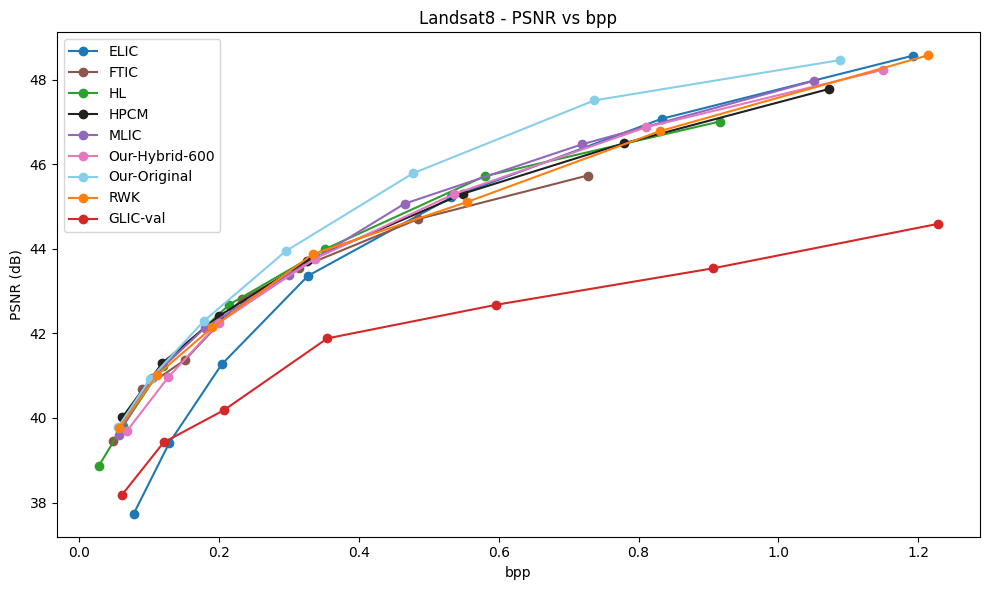

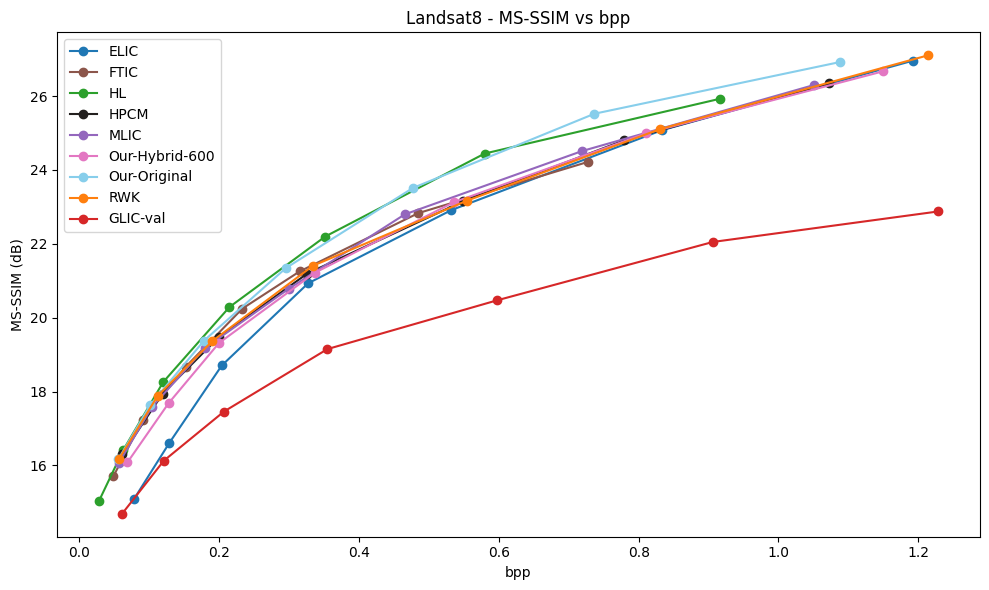

In [5]:
# 画图方式保持原来的两张独立曲线图。
datasets = dict(landsat8_full_test_1700)
datasets['GLIC-val'] = glic_landsat8_val
colors = {
    'ELIC': '#1f77b4', 'RWK': '#ff7f0e', 'HL': '#2ca02c',
    'MLIC': '#9467bd', 'FTIC': '#8c564b', 'HPCM': '#23201f',
    'Our-Original': 'skyblue', 'Our-Hybrid-600': '#e377c2',
    'GLIC-val': '#d62728',
}
plt.figure(figsize=(10, 6))
for name, data in datasets.items():
    bpp, psnr, _ = zip(*data)
    plt.plot(bpp, psnr, label=name, marker='o', color=colors.get(name, None))
plt.xlabel('bpp'); plt.ylabel('PSNR (dB)')
plt.title('Landsat8 - PSNR vs bpp'); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 6))
for name, data in datasets.items():
    bpp, _, msssim = zip(*data)
    plt.plot(bpp, msssim, label=name, marker='o', color=colors.get(name, None))
plt.xlabel('bpp'); plt.ylabel('MS-SSIM (dB)')
plt.title('Landsat8 - MS-SSIM vs bpp'); plt.legend(); plt.tight_layout(); plt.show()